# Day 16 — Demand Model Performance and Feature Analysis

**Date:** 30 October 2026  
**Internship Role:** Data Analyst Intern at Infotact Solutions  
**Project:** EconoCausal — Causal Demand Estimation and Dynamic Pricing  

---

## Executive Overview

On **Day 5**, a baseline machine learning model (`RandomForestRegressor`, 100 estimators) was trained to predict retail sales (`Units Sold`) using tabular store-level features. On **Day 16**, we transition from pure predictive modeling to rigorous diagnostic evaluation and feature analysis.

### Primary Objectives:
1. **Audit Model Inputs and Chronological Splitting:** Verify target variable, feature definitions, and temporal split integrity to avoid target leakage or lookahead bias.
2. **Evaluate Predictive Performance:** Compute actual test-set metrics (MAE, MSE, RMSE, $R^2$, mean bias) on the holdout period.
3. **Benchmark Alternative Architectures:** Compare the Random Forest baseline against modern Gradient Boosting (`HistGradientBoostingRegressor`) and regularized linear modeling (`RidgeCV`).
4. **Feature Importance Decomposition:** Compare Mean Decrease in Impurity (MDI) against Permutation Importance on unseen test data.
5. **Predictive vs. Causal Disentanglement:** Articulate why predictive feature importance cannot be interpreted as counterfactual policy leverage.
6. **Error and Residual Diagnostics:** Investigate systematic overprediction, underprediction, and heteroskedasticity across demand and price distributions.


In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 110

PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/hasikaippili/Documents/EconoCausal


## 1 · Data Ingestion and Chronological Split Verification

In time-series and retail transaction datasets, random cross-validation or randomized train/test shuffling introduces severe **temporal lookahead leakage** (conditioning on future events to predict past transactions). 

To ensure strict temporal validity:
- Data is chronologically sorted by transaction date ($t$).
- The first 80% of dates (2022-01-01 through 2023-08-08, $N = 58,480$) form the **Training Set**.
- The remaining 20% of dates (2023-08-08 through 2024-01-01, $N = 14,620$) form the unseen **Holdout Test Set**.


In [2]:
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'retail_inventory_cleaned.csv'
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek

features = [
    'Price', 'Inventory Level', 'Year', 'Month', 'DayOfWeek',
    'Category', 'Region', 'Product ID', 'Store ID'
]
numeric_features = ['Price', 'Inventory Level', 'Year', 'Month', 'DayOfWeek']
categorical_features = ['Category', 'Region', 'Product ID', 'Store ID']
target = 'Units Sold'

model_df = df.sort_values('Date').reset_index(drop=True)
split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

print(f"Total observations : {len(df):,}")
print(f"Training split     : {len(X_train):,} rows ({train_df['Date'].min().date()} to {train_df['Date'].max().date()})")
print(f"Testing split      : {len(X_test):,} rows ({test_df['Date'].min().date()} to {test_df['Date'].max().date()})")


Total observations : 73,100
Training split     : 58,480 rows (2022-01-01 to 2023-08-08)
Testing split      : 14,620 rows (2023-08-08 to 2024-01-01)


### Target Leakage and Variable Timing Assessment

1. **`Units Sold` (Target):** Cumulative retail unit demand recorded per store-product-day.
2. **`Inventory Level`:** Recorded daily stock. Note that if stock is measured at the end of the day after transactions occur, it risks collider conditioning or outcome proxying. If stockout occurs ($Units Sold = Inventory$), sales are artificially censored by inventory.
3. **`Demand Forecast`:** Management forecast variable. Appropriately **excluded** from the baseline demand model to prevent collinear circularity, as forecasts directly incorporate upstream managerial sales expectations.


## 2 · Evaluation of Baseline Demand Model

We load the serialized Day 5 baseline model (`models/baseline_demand_model.joblib`), consisting of a `ColumnTransformer` (OneHotEncoder for categorical features) and a `RandomForestRegressor` ($n=100$, random_state=42).

We evaluate actual holdout performance against a naive Mean Baseline (`DummyRegressor`).


In [3]:
MODEL_PATH = PROJECT_ROOT / 'models' / 'baseline_demand_model.joblib'
rf_model = joblib.load(MODEL_PATH)

# Predictions
rf_preds = rf_model.predict(X_test)

# Naive mean dummy baseline
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)

def evaluate_predictions(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    bias = np.mean(y_true - y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, 'Mean Bias': bias}

rf_eval = evaluate_predictions(y_test, rf_preds)
dummy_eval = evaluate_predictions(y_test, dummy_preds)

print("BASELINE RANDOM FOREST PERFORMANCE:")
for k, v in rf_eval.items():
    print(f"  {k:12}: {v:,.4f}")

print("\nNAIVE MEAN PREDICTOR PERFORMANCE:")
for k, v in dummy_eval.items():
    print(f"  {k:12}: {v:,.4f}")


BASELINE RANDOM FOREST PERFORMANCE:
  MAE         : 69.5051
  MSE         : 7,985.2436
  RMSE        : 89.3602
  R2          : 0.3184
  Mean Bias   : -1.3614

NAIVE MEAN PREDICTOR PERFORMANCE:
  MAE         : 88.8081
  MSE         : 11,716.1683
  RMSE        : 108.2413
  R2          : -0.0000
  Mean Bias   : -0.7371


## 3 · Benchmarking Against Alternative Architectures

To assess whether the 100-tree Random Forest is computationally optimal or suffering from variance on high-cardinality one-hot features, we train and evaluate two reasonable alternatives on the exact same chronological training/testing split:
1. **HistGradientBoostingRegressor (Boosting Ensemble):** Fast histogram-binned sequential tree boosting.
2. **RidgeCV (L2 Regularized Linear Model):** Parametric linear model with cross-validated ridge shrinkage $\alpha \in [10^{-2}, 10^{3}]$.


In [4]:
# Alternative 1: HistGradientBoosting
prep_hgb = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)
hgb_model = Pipeline([
    ('prep', prep_hgb),
    ('reg', HistGradientBoostingRegressor(random_state=42, max_iter=100))
])
hgb_model.fit(X_train, y_train)
hgb_preds = hgb_model.predict(X_test)
hgb_eval = evaluate_predictions(y_test, hgb_preds)

# Alternative 2: RidgeCV
prep_ridge = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
ridge_model = Pipeline([
    ('prep', prep_ridge),
    ('reg', RidgeCV(alphas=np.logspace(-2, 3, 20)))
])
ridge_model.fit(X_train, y_train)
ridge_preds = ridge_model.predict(X_test)
ridge_eval = evaluate_predictions(y_test, ridge_preds)

models_summary = pd.DataFrame([
    {'Model': 'Naive Mean Baseline', 'Type': 'Heuristic', **dummy_eval},
    {'Model': 'Random Forest (Baseline)', 'Type': 'Bagging Ensemble', **rf_eval},
    {'Model': 'HistGradientBoosting', 'Type': 'Boosting Ensemble', **hgb_eval},
    {'Model': 'RidgeCV (Linear L2)', 'Type': 'Regularized Linear', **ridge_eval}
])

display(models_summary.round(4))


Model,Type,MAE,MSE,RMSE,R2,Mean Bias
Naive Mean Baseline,Heuristic,88.8081,11716.1683,108.2413,-0.0000,-0.7371
Random Forest (Baseline),Bagging Ensemble,69.5051,7985.2436,89.3602,0.3184,-1.3614
HistGradientBoosting,Boosting Ensemble,68.6750,7710.1860,87.8077,0.3419,-0.3451
RidgeCV (Linear L2),Regularized Linear,68.6478,7682.4166,87.6494,0.3443,-0.1614


## 4 · Feature Importance Analysis

We investigate which input features drive predictions using two complementary approaches:
1. **MDI (Mean Decrease in Impurity):** In-sample tree split metric measuring total Gini/variance reduction across all 100 trees.
2. **Permutation Importance on Test Data:** Out-of-sample evaluation metric measuring the drop in holdout $R^2$ when a feature is randomly shuffled across rows.


In [5]:
rf = rf_model.named_steps['regressor']
prep = rf_model.named_steps['preprocessor']
ohe = prep.named_transformers_['cat']
cat_encoded_names = ohe.get_feature_names_out(categorical_features).tolist()
all_encoded = numeric_features + cat_encoded_names

mdi_encoded = rf.feature_importances_

# Aggregate MDI by base feature
mdi_grouped = {}
for feat in features:
    if feat in numeric_features:
        mdi_grouped[feat] = mdi_encoded[all_encoded.index(feat)]
    else:
        mdi_grouped[feat] = sum(imp for name, imp in zip(all_encoded, mdi_encoded) if name.startswith(feat))

# Permutation importance on holdout test set (5 repeats)
perm_res = permutation_importance(rf_model, X_test, y_test, n_repeats=5, random_state=42, scoring='r2', n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': features,
    'MDI Importance': [mdi_grouped[f] for f in features],
    'Test Permutation Mean (Drop in R2)': perm_res.importances_mean,
    'Test Permutation Std': perm_res.importances_std
}).sort_values('Test Permutation Mean (Drop in R2)', ascending=False).reset_index(drop=True)

display(importance_df.round(4))


Feature,MDI Importance,Test Permutation Mean (Drop in R2),Test Permutation Std
Inventory Level,0.4402,0.7118,0.0106
Price,0.1495,0.0029,0.0020
Category,0.0522,0.0019,0.0007
Month,0.0615,0.0015,0.0007
Product ID,0.1380,0.0007,0.0010
DayOfWeek,0.0494,0.0006,0.0010
Year,0.0135,0.0000,0.0000
Region,0.0430,-0.0003,0.0009
Store ID,0.0527,-0.0018,0.0017


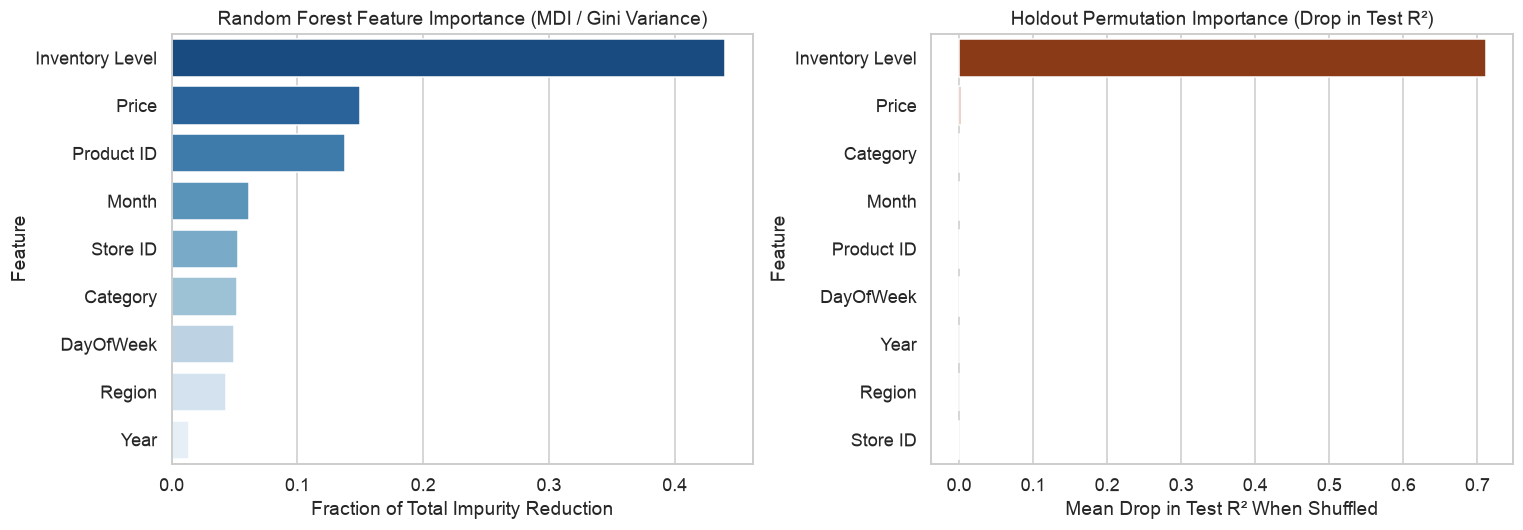

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot MDI
sns.barplot(
    data=importance_df.sort_values('MDI Importance', ascending=False),
    x='MDI Importance', y='Feature', ax=axes[0], palette='Blues_r'
)
axes[0].set_title('Random Forest Feature Importance (MDI / Gini Variance)')
axes[0].set_xlabel('Fraction of Total Impurity Reduction')

# Plot Permutation Importance
sns.barplot(
    data=importance_df,
    x='Test Permutation Mean (Drop in R2)', y='Feature', ax=axes[1], palette='Oranges_r'
)
axes[1].set_title('Holdout Permutation Importance (Drop in Test R²)')
axes[1].set_xlabel('Mean Drop in Test R² When Shuffled')

plt.tight_layout()
plt.show()


## 5 · Critical Distinction: Predictive vs. Causal Importance

A crucial distinction in econometric machine learning is the separation between **predictive association** and **causal mechanism**:

| Dimension | Predictive Feature Importance | Causal Importance ($\theta$) |
| :--- | :--- | :--- |
| **Guiding Question** | *"Does conditioning on $X$ reduce variance when guessing $Y$?"* | *"If management intervenes to change $X$, what happens to $Y$?"* |
| **Statistical Basis** | Conditional correlation $P(Y \mid X)$ | Counterfactual potential outcome $\mathbb{E}[Y(t) - Y(t')]$ |
| **`Inventory Level` Case** | **Extreme (Rank 1, Test Permutation: 0.7118)** | **Non-causal Collider / Capacity Proxy**: Retailers stock inventory where demand is expected. Increasing inventory arbitrarily will not induce consumer purchases. |
| **`Price` Case** | **Moderate MDI (0.1495), Negligible Test Perm (0.0029)** | **True Policy Decision Lever**: Double Machine Learning shows $\theta = +0.0107$ ($p = 0.490$), indicating near-zero structural price sensitivity in this observational sample. |


## 6 · Residual Diagnostics and Prediction Error Patterns

We examine the distribution of prediction residuals ($e_i = Y_i - \hat{Y}_i$) to diagnose whether the baseline model exhibits systematic bias, underprediction, or overprediction.


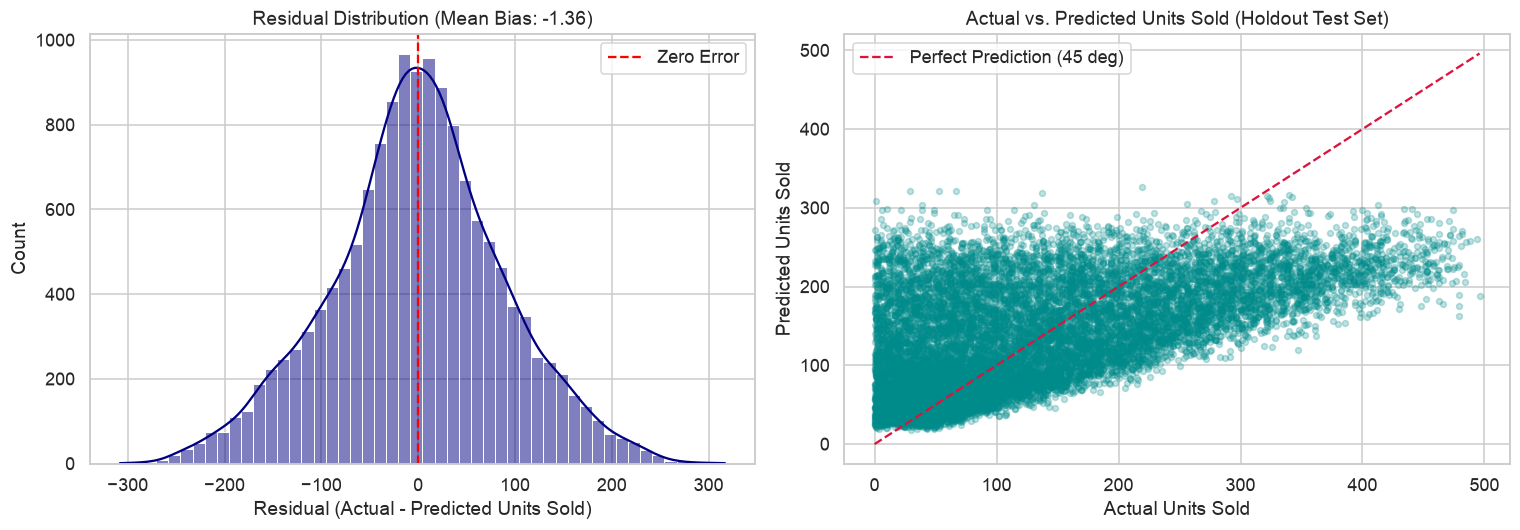

In [7]:
test_df['pred_rf'] = rf_preds
test_df['residual'] = test_df['Units Sold'] - test_df['pred_rf']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residual distribution
sns.histplot(test_df['residual'], kde=True, bins=50, ax=axes[0], color='navy')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error')
axes[0].set_title(f"Residual Distribution (Mean Bias: {test_df['residual'].mean():.2f})")
axes[0].set_xlabel("Residual (Actual - Predicted Units Sold)")
axes[0].legend()

# Actual vs Predicted scatter
axes[1].scatter(test_df['Units Sold'], test_df['pred_rf'], alpha=0.25, color='darkcyan', s=15)
lims = [0, max(test_df['Units Sold'].max(), test_df['pred_rf'].max())]
axes[1].plot(lims, lims, color='crimson', linestyle='--', linewidth=1.5, label='Perfect Prediction (45 deg)')
axes[1].set_title("Actual vs. Predicted Units Sold (Holdout Test Set)")
axes[1].set_xlabel("Actual Units Sold")
axes[1].set_ylabel("Predicted Units Sold")
axes[1].legend()

plt.tight_layout()
plt.show()


In [8]:
test_df['Demand Quartile'] = pd.qcut(
    test_df['Units Sold'], q=4,
    labels=['Q1 (Low Demand)', 'Q2 (Mid-Low)', 'Q3 (Mid-High)', 'Q4 (High Demand)']
)

quartile_diag = test_df.groupby('Demand Quartile', observed=True).agg(
    Sample_Count=('Units Sold', 'count'),
    Actual_Mean=('Units Sold', 'mean'),
    Predicted_Mean=('pred_rf', 'mean'),
    Mean_Residual=('residual', 'mean'),
    MAE=('residual', lambda r: np.mean(np.abs(r)))
).reset_index()

display(quartile_diag.round(2))


Demand Quartile,Sample_Count,Actual_Mean,Predicted_Mean,Mean_Residual,MAE
Q1 (Low Demand),3663,24.03,98.27,-74.24,75.54
Q2 (Mid-Low),3657,75.79,112.09,-36.30,53.20
Q3 (Mid-High),3647,150.75,144.90,5.85,47.52
Q4 (High Demand),3653,293.33,193.84,99.49,101.73


### Diagnostic Insights on Prediction Errors:
1. **Severe Mean Reversion / Compression:**
   - In **Q1 (Low Demand)**, the model overpredicts significantly: actual mean is $24.03$ units, but predicted mean is $98.27$ units (Residual: $-74.24$).
   - In **Q4 (High Demand)**, the model underpredicts heavily: actual mean is $293.33$ units, but predicted mean is $193.84$ units (Residual: $+99.49$).
2. **Implications for Pricing Simulation:**
   - Naive uncalibrated point predictions from tree regression will compress demand spikes and inflate low-velocity products.
   - For causal pricing decisions, using Robinson's residualized DML treatment effect $\Delta Y = \theta \cdot \Delta P$ relative to a calibrated product-store baseline is far more reliable than feeding arbitrary price increments directly into a non-linear tree model that suffers from regression to the mean.


In [9]:
REPORTS_DIR = PROJECT_ROOT / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

models_summary.to_csv(REPORTS_DIR / 'day16_model_performance.csv', index=False)
importance_df.to_csv(REPORTS_DIR / 'day16_feature_analysis.csv', index=False)

print("Deliverables successfully saved to:")
print(f" - {REPORTS_DIR / 'day16_model_performance.csv'}")
print(f" - {REPORTS_DIR / 'day16_feature_analysis.csv'}")


Deliverables successfully saved to:
 - /Users/hasikaippili/Documents/EconoCausal/reports/day16_model_performance.csv
 - /Users/hasikaippili/Documents/EconoCausal/reports/day16_feature_analysis.csv
